In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
cd /content/drive/MyDrive/OpenFedFLASK/FLASK/gpt_review

/content/drive/MyDrive/OpenFedFLASK/FLASK/gpt_review


# 원하는 모델의 CSV 생성

In [ ]:
#====================사용자의 입력 필요====================
#평가가 완료된 모델 이름
model_1 = "Prometheus_FlaskDataset_c5s3"
model_2 = "Prometheus_FlaskDataset"
model_3 = "Mistral_FlaskDataset_c5s3"
model_4 = "Mistral_FlaskDataset"
model_name = model_1

#질문의 개수
question_num = 1000

#연합 학습 라운드 횟수 - 일반 모델의 경우 0
iteration = 10
#==========================================================

#리뷰 JSON 파일의 경로
review_file = f"/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/{model_name}/q{question_num}_i{iteration}/review.jsonl"

#스킬 CSV 파일의 저장 경로
output_path = f"/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/{model_name}/q{question_num}_i{iteration}/"

In [ ]:
!python aggregate_skill.py --file $review_file --output $output_path

readability
logical correctness
conciseness
commonsense understanding
comprehension
factuality
insightfulness
completeness
logical efficiency
logical robustness
harmlessness
metacognition
length issue!!! {'communication': 4, 'teamwork': 4, 'flexibility': 4, 'adaptability': 4, 'self-motivation': 4, 'creativity': 4, 'problem-solving': 4, 'leadership': 3, 'multitasking': 4, 'organization': 4, 'physical ability': 4, 'time management': 4, 'attention to detail': 4, 'negotiation': 3, 'customer service': 4, 'planning': 4, 'prioritization': 4, 'technical': 4, 'safety': 4, 'first aid': 3} {'idx': 173, 'instruction': 'Provide a list of the skills that may help you find the job.\nInput: Crew Members', 'answer': 'Baking\nBasic math\nBilingual\nCash handling\nCashiering\nCommunication skills\nComputer literacy\nComputer skills\nConstruction\nCooking\nCustomer service', 'task': 'Self-instruct', 'skill': ['Comprehension', 'Factuality', 'Readability'], 'domain': ['Humanities', 'Social Science'], 'diffi

In [ ]:
!python aggregate_domain.py --file $review_file --output $output_path

Humanities	1884.0	588
Language	1119.0	363
Social Science	1455.0	468
History	500.0	165
Culture	1940.0	633
Technology	1801.0	606
Coding	1208.0	390
Math	961.0	393
Natural Science	971.0	309
Health	753.0	228


# CSV 시각화 함수

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [4]:
def draw_radar_chart(file_path):
    # CSV 파일을 로드합니다.
    data = pd.read_csv(file_path)

    # 성능 지표 추출
    categories = ['correctness', 'factuality', 'commonsense', 'comprehension',
                'insightfulness', 'completeness', 'readability', 'conciseness']

    filtered_data = data[data['skill'].isin(categories)]
    values = filtered_data['avg'].values

    # 레이더 차트를 생성합니다.
    num_vars = len(categories)

    # 각 성능 지표에 대한 각도를 계산합니다.
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

    # 차트를 원형으로 만들기 위해 시작 값을 끝에 추가합니다.
    values = np.concatenate((values, [values[0]]))
    angles += angles[:1]

    # 플로팅
    fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))

    name = file_path.split('.csv')[0].split('/')[-1]

    # 데이터를 플롯하고 채웁니다.
    ax.plot(angles, values, color='b', linewidth=2, linestyle='solid', label=name)
    ax.fill(angles, values, color='b', alpha=0.25)

    # 각 축의 레이블을 설정합니다.
    ax.set_yticks(np.arange(1, 6, 1))  # 1칸에 1점씩 표시되도록 수정
    ax.set_yticklabels(range(1, 6), fontsize=16, weight='bold')
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([f'{category}' for category in categories], fontsize=14, weight='bold', color='blue')

    # 범례 추가
    ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

    # 제목 설정
    plt.title("Performance BenchMark by Skills", size=20, weight='bold', position=(0.5, 1.1))

    # 차트를 표시합니다.
    plt.show()

In [9]:
def draw_bar_chart(file_path):
    data = pd.read_csv(file_path)

    categories = ['Humanities', 'Language', 'Culture', 'Technology']

    filtered_data = data[data['domain'].isin(categories)]
    values = filtered_data['avg'].values

    num_vars = len(categories)

    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

    values = np.concatenate((values, [values[0]]))
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))

    ax.plot(angles, values, color='#FF6F61', linewidth=2, linestyle='solid', label='Prometheus')
    ax.fill(angles, values, color='#FF6F61', alpha=0.25)

    ax.set_yticks(np.arange(1, 6, 1))
    ax.set_yticklabels(range(1, 6), fontsize=12, weight='bold')
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([f'{category}' for category in categories], fontsize=14, weight='bold', color='darkblue')

    ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.title("Performance Benchmark by Domain - Prometheus", size=20, weight='bold', position=(0.5, 1.1))
    plt.show()

# Prometheus 시각화 결과 예시

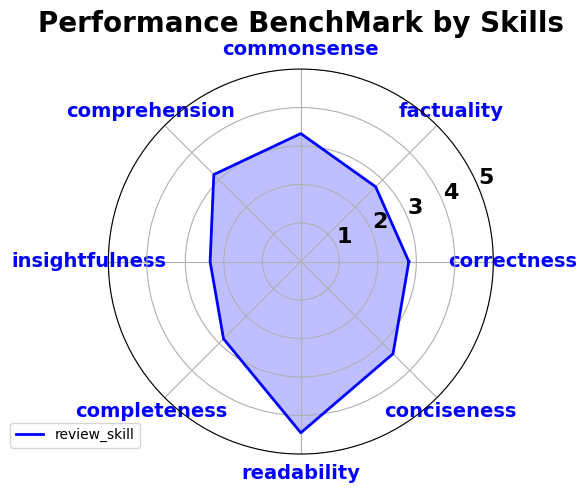

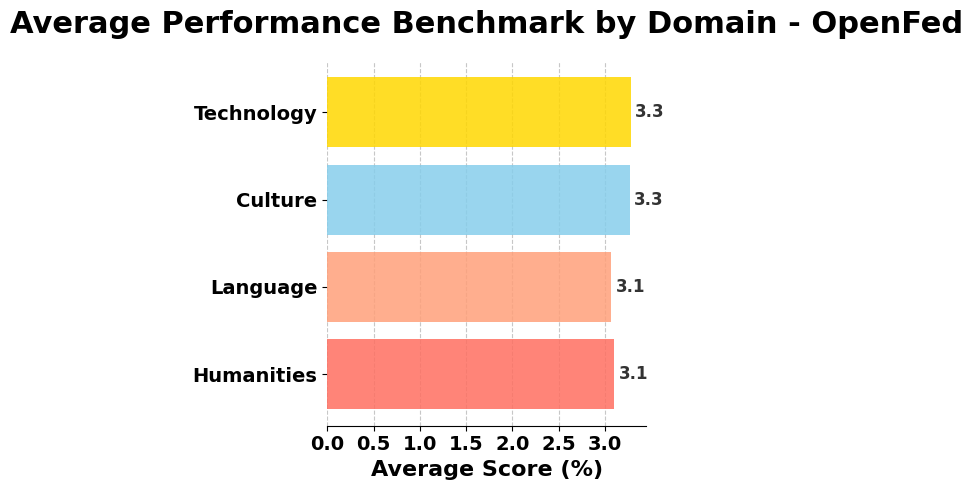

In [ ]:
#Prometheus-7b-v2.0
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset/q1000_i0/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset/q1000_i0/content_domain.csv")

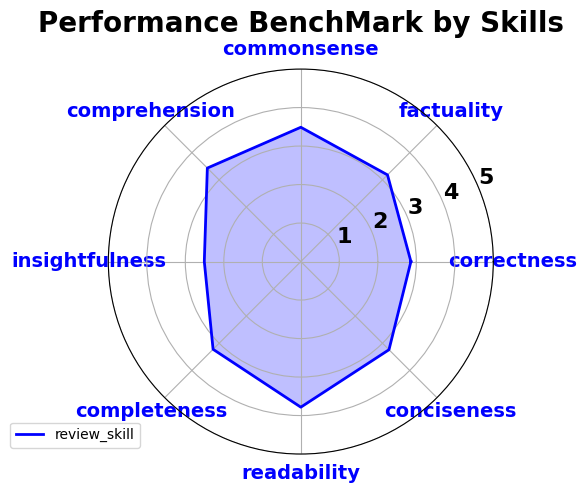

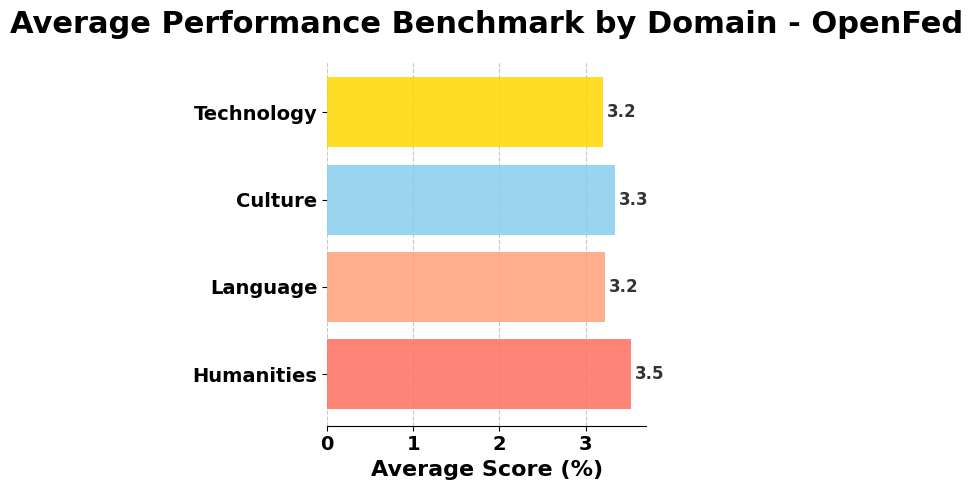

In [ ]:
#OpenFedPro_c5s3_q1000_i1
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i1/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i1/content_domain.csv")

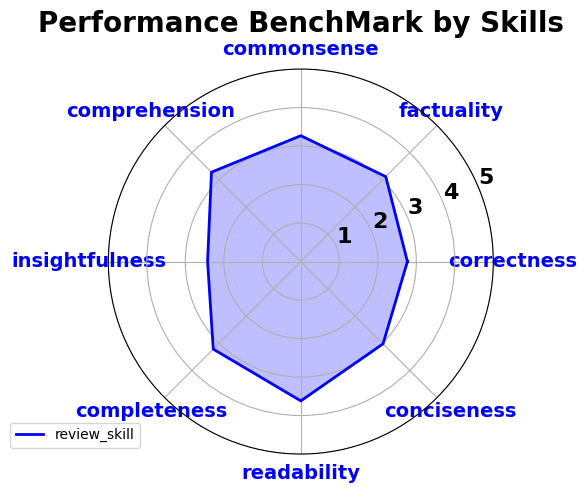

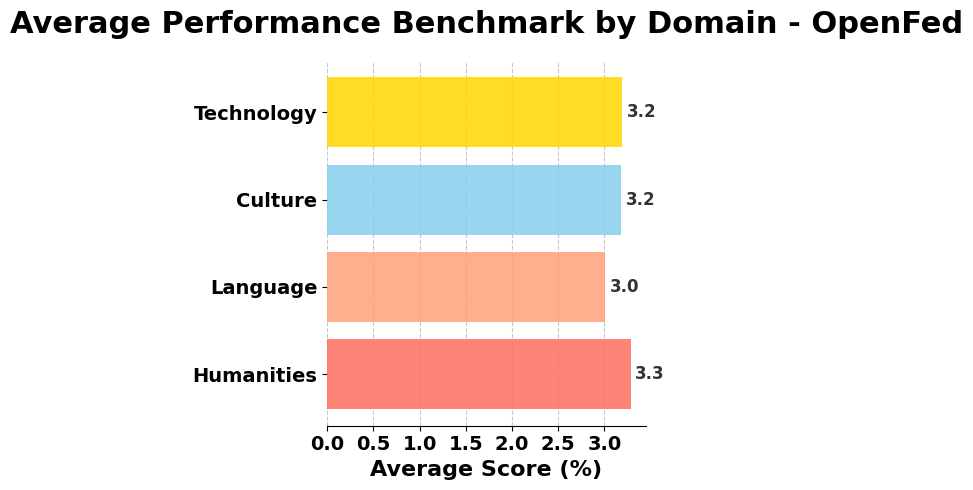

In [ ]:
#OpenFedPro_c5s3_q1000_i3
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i3/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i3/content_domain.csv")

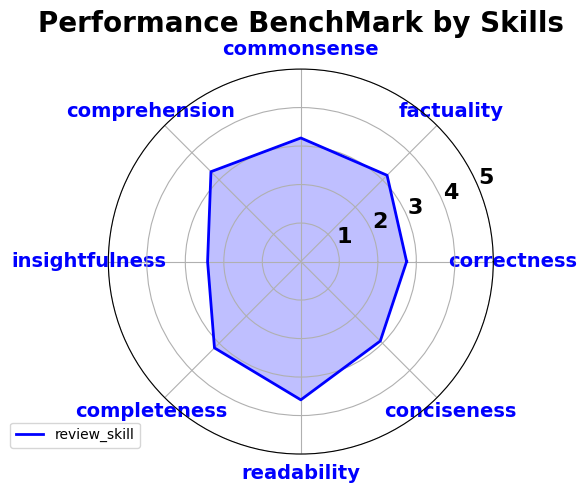

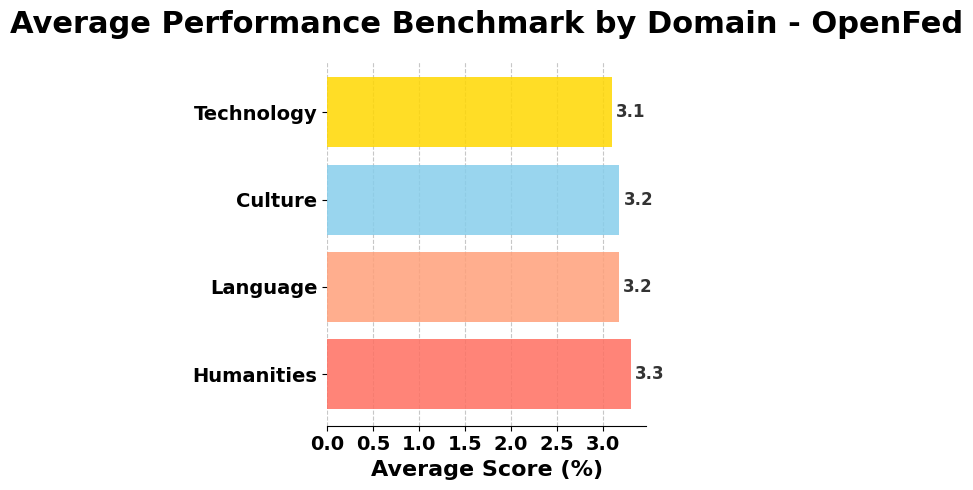

In [ ]:
#OpenFedPro_c5s3_q1000_i5
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i5/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i5/content_domain.csv")

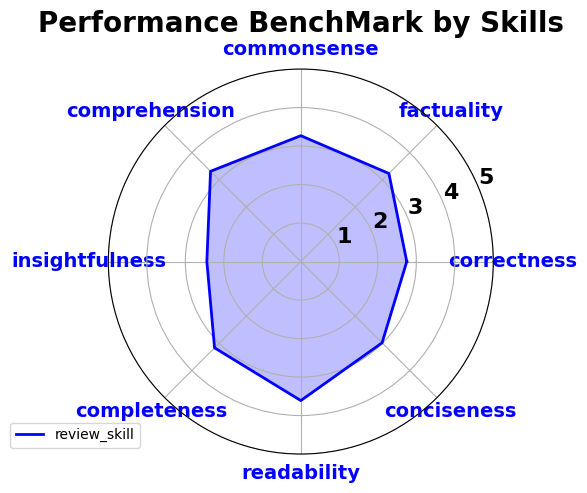

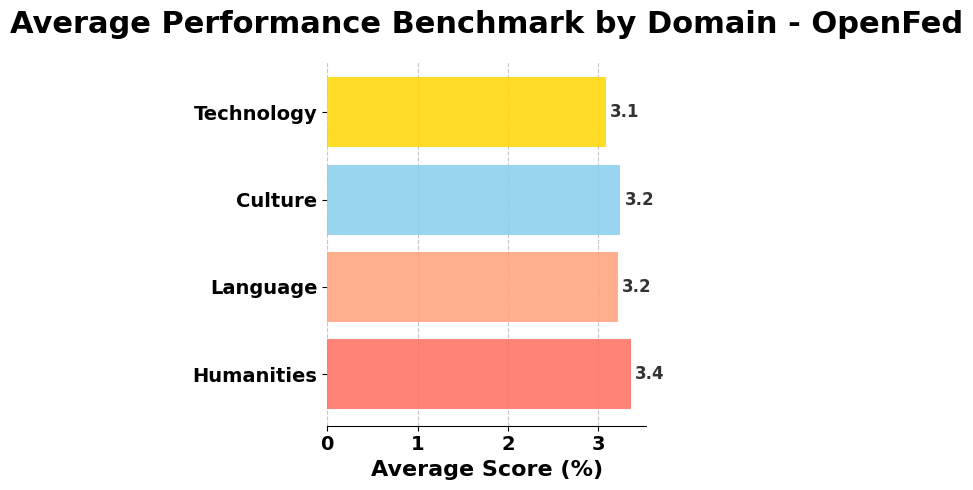

In [ ]:
#OpenFedPro_c5s3_q1000_i7
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i7/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i7/content_domain.csv")

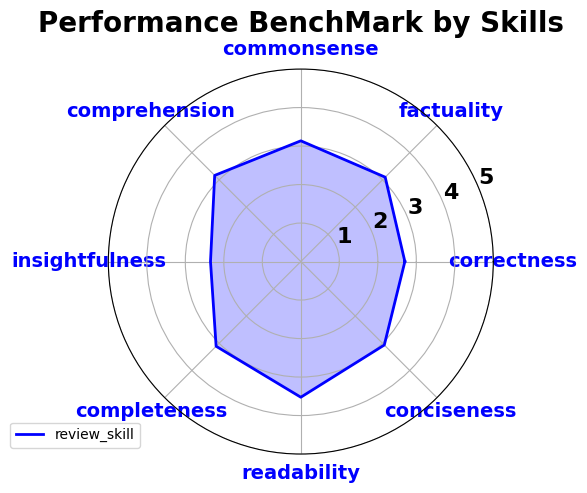

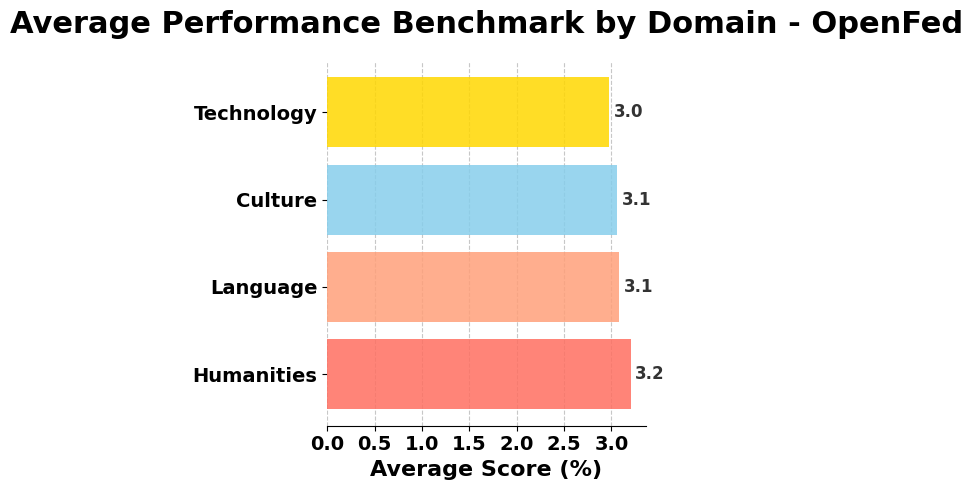

In [ ]:
#OpenFedPro_c5s3_q1000_i10
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i10/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Prometheus_FlaskDataset_c5s3/q1000_i10/content_domain.csv")

# Mistral 시각화 예시


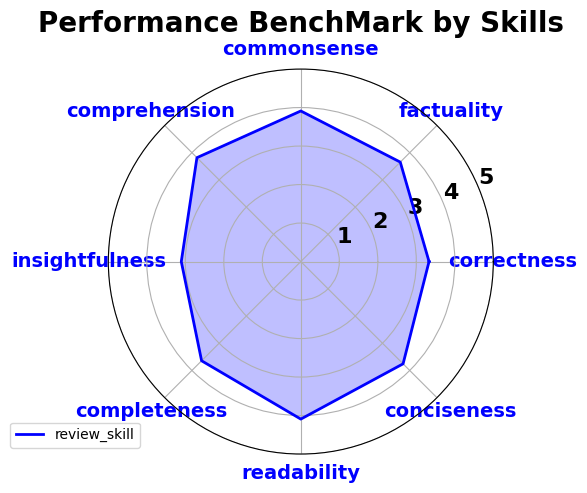

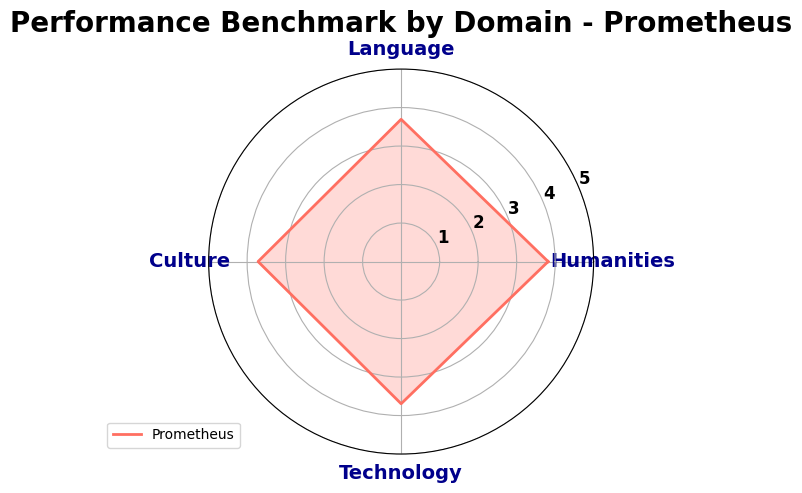

In [17]:
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset/q1000_i0/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset/q1000_i0/content_domain.csv")

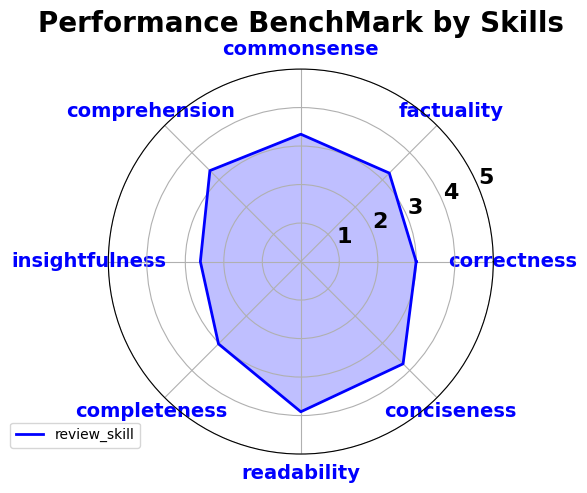

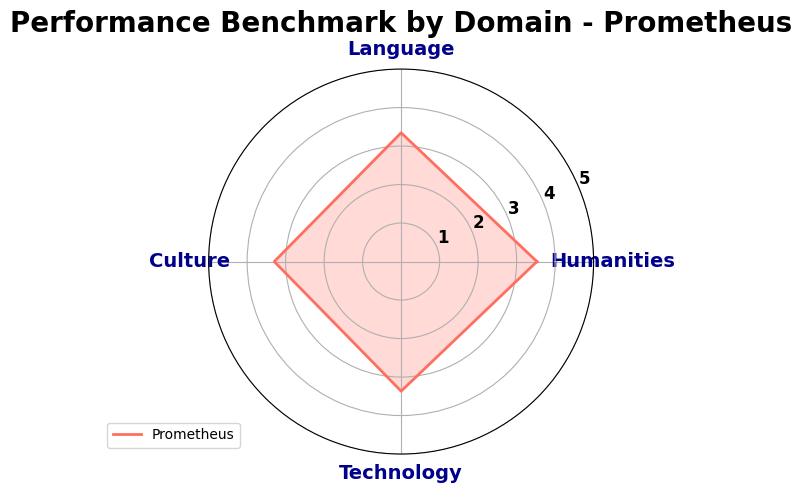

In [18]:
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i1/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i1/content_domain.csv")

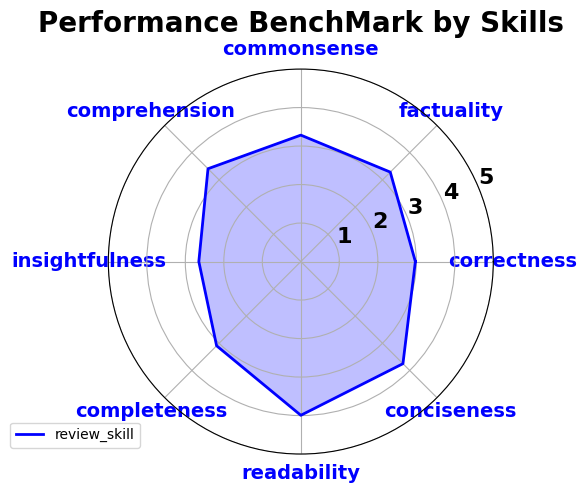

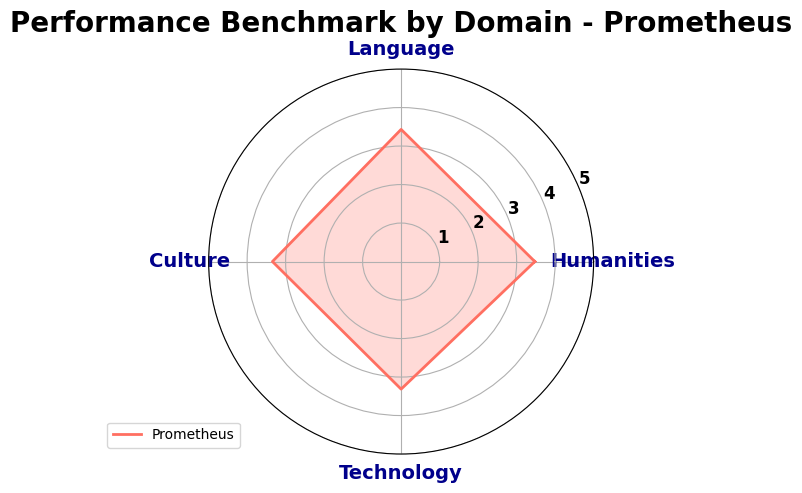

In [19]:
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i3/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i3/content_domain.csv")

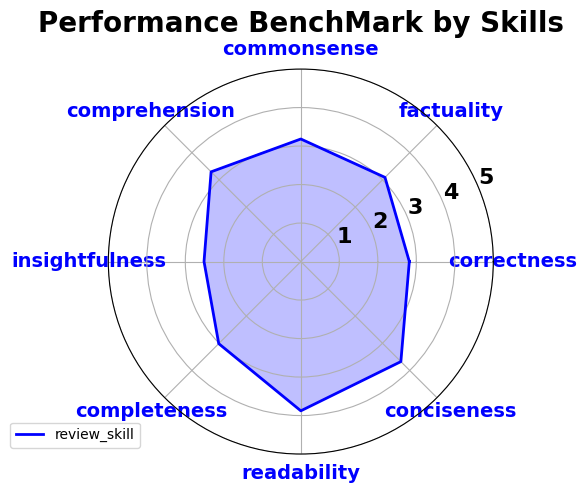

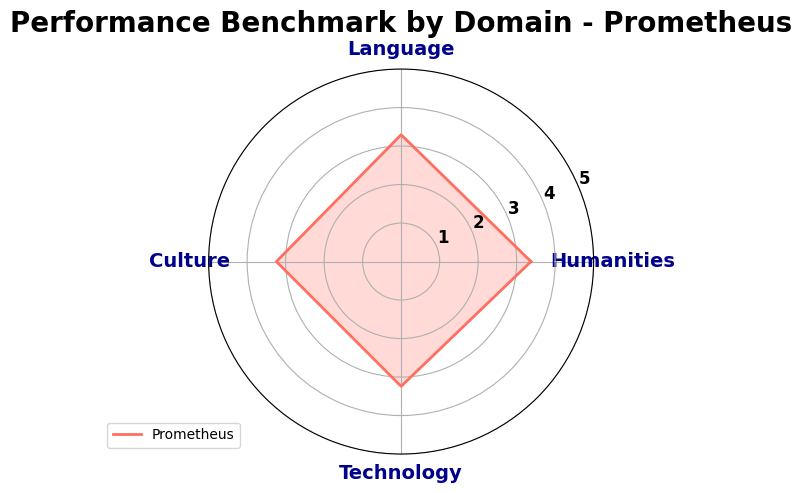

In [20]:
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i5/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i5/content_domain.csv")

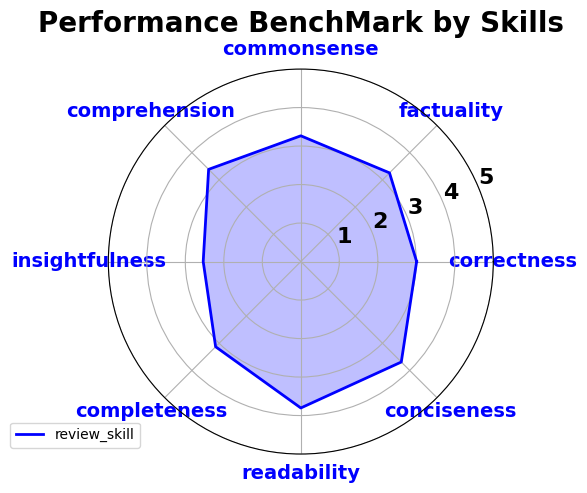

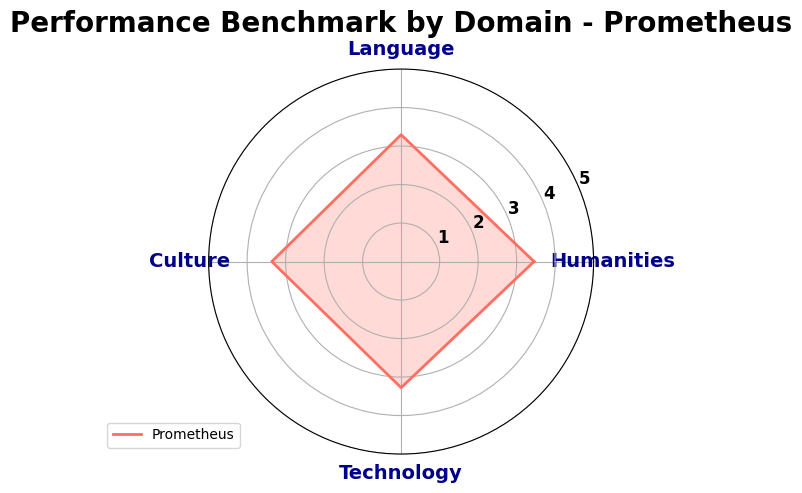

In [21]:
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i7/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i7/content_domain.csv")

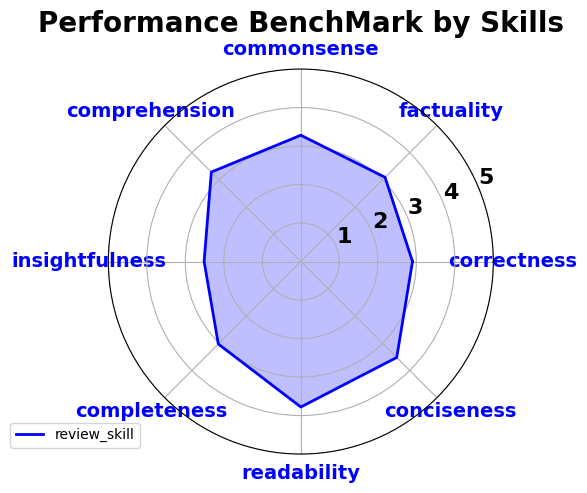

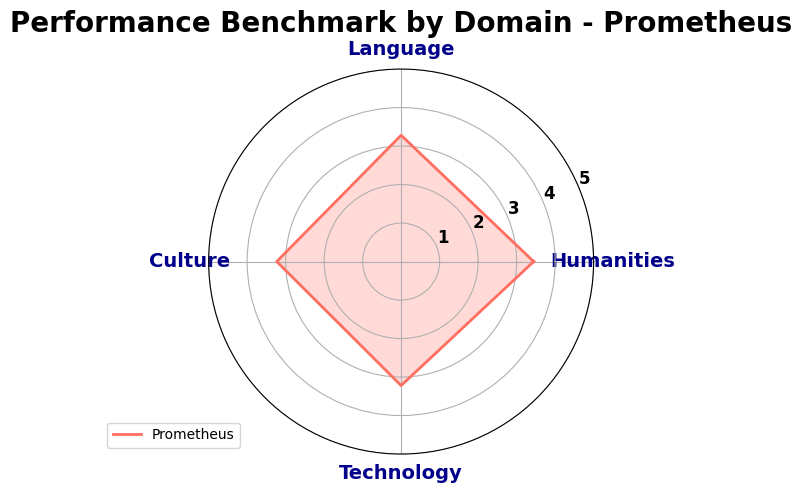

In [15]:
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i10/review_skill.csv")
draw_bar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/Mistral_FlaskDataset_c5s3/q1000_i10/content_domain.csv")

# gpt4 시각화 결과 예시


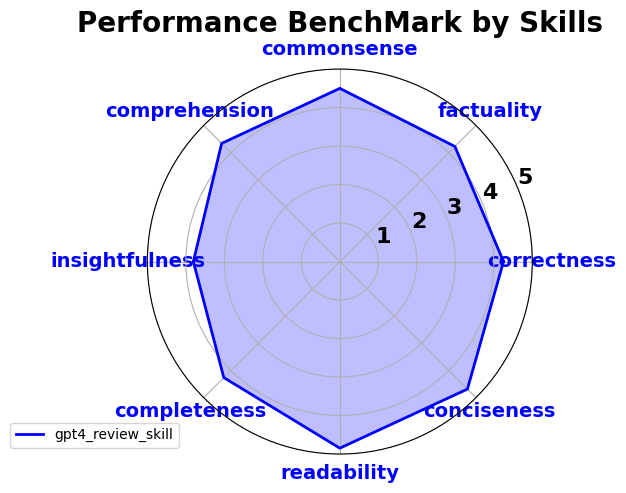

In [16]:
#gpt4_review_skill
draw_radar_chart("/content/drive/MyDrive/OpenFedFLASK/flask_evaluation_outputs/gpt4_review_skill.csv")